# Telecom Churn Prediction
# Classification model

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df =pd.read_csv("Downloads/Telcom-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.shape

(7043, 21)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df["TotalCharges"].unique()

<StringArray>
[  '29.85',  '1889.5',  '108.15', '1840.75',  '151.65',   '820.5',  '1949.4',
   '301.9', '3046.05', '3487.95',
 ...
 '2625.25', '6886.25',  '1495.1',   '743.3',  '1419.4',  '1990.5',  '7362.9',
  '346.45',   '306.6',  '6844.5']
Length: 6531, dtype: str

In [7]:
df["TotalCharges"] =df["TotalCharges"].replace(" ",np.nan,inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_5676\1312677349.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["TotalCharges"] =df["TotalCharges"].replace(" ",np.nan,inplace=True)


In [8]:
df["TotalCharges"]=pd.to_numeric(df["TotalCharges"],errors="coerce")

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
# Duplicate value
df.duplicated().sum()

np.int64(0)

In [11]:
# Check missing value
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [12]:
df[df['TotalCharges'].isnull()]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


<Axes: >

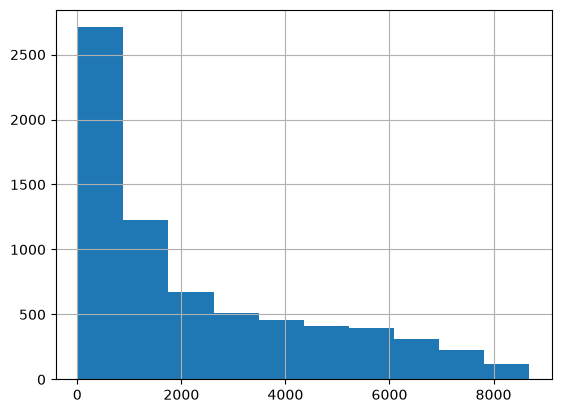

In [13]:
df["TotalCharges"].hist()

In [14]:
median =df["TotalCharges"].median()

In [15]:
df["TotalCharges"] =df["TotalCharges"].fillna(median,inplace=True)

C:\Users\hp\AppData\Local\Temp\ipykernel_5676\4162120183.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df["TotalCharges"] =df["TotalCharges"].fillna(median,inplace=True)


In [16]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [17]:
df["OnlineSecurity"].value_counts()

OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

In [18]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


<Axes: xlabel='TotalCharges'>

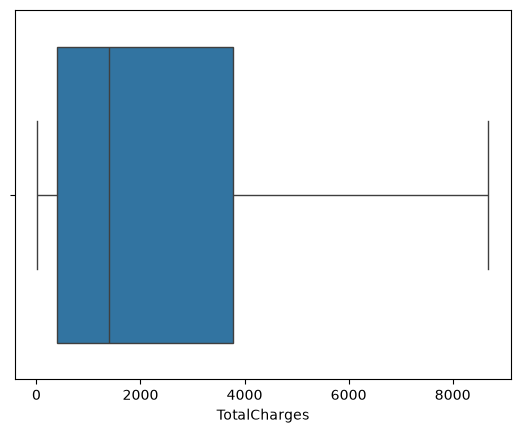

In [19]:
sns.boxplot(x= "TotalCharges",data=df)

<Axes: xlabel='MonthlyCharges'>

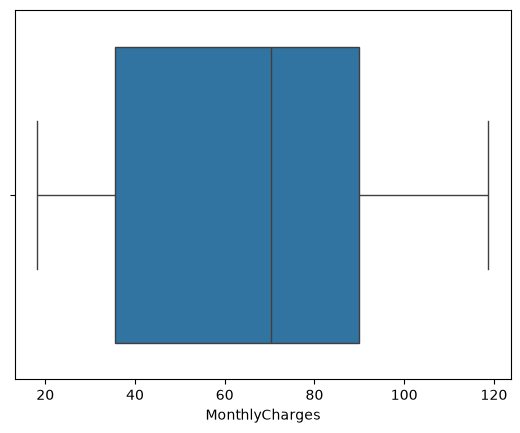

In [20]:
sns.boxplot(x= "MonthlyCharges",data=df)

In [21]:
df["TotalCharges"].unique()

array([  29.85, 1889.5 ,  108.15, ...,  346.45,  306.6 , 6844.5 ],
      shape=(6531,))

In [22]:
df_num =df.select_dtypes(['int64','float64'])
df_cat =df.select_dtypes(str)

In [23]:
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,7590-VHVEG,Female,Yes,No,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,No
1,5575-GNVDE,Male,No,No,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,No
2,3668-QPYBK,Male,No,No,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,Yes
3,7795-CFOCW,Male,No,No,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),No
4,9237-HQITU,Female,No,No,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,Yes,Yes,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,No
7039,2234-XADUH,Female,Yes,Yes,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),No
7040,4801-JZAZL,Female,Yes,Yes,No,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,Yes,Electronic check,No
7041,8361-LTMKD,Male,Yes,No,Yes,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Mailed check,Yes


In [24]:
df_num

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65
...,...,...,...,...
7038,0,24,84.80,1990.50
7039,0,72,103.20,7362.90
7040,0,11,29.60,346.45
7041,1,4,74.40,306.60


# Encoding 

In [25]:
from sklearn.preprocessing import LabelEncoder

In [26]:
le =LabelEncoder()

In [27]:
for i in df_cat:
    

    df_cat[i] =le.fit_transform(df_cat[i])

In [28]:
df_cat

,customerID,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,5375,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,3962,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,2564,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,5535,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,6511,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,4853,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,1525,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,3367,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,5934,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [29]:
df_cat =df_cat.drop(columns="customerID")

In [30]:
df_cat

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1


In [31]:
df_num

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,29.85,29.85
1,0,34,56.95,1889.50
2,0,2,53.85,108.15
3,0,45,42.30,1840.75
4,0,2,70.70,151.65
...,...,...,...,...
7038,0,24,84.80,1990.50
7039,0,72,103.20,7362.90
7040,0,11,29.60,346.45
7041,1,4,74.40,306.60


In [32]:
# Combine num col and cat col

df_new =pd.concat([df_cat,df_num],axis=1)
df_new

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,0,1,29.85,29.85
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,0,34,56.95,1889.50
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1,0,2,53.85,108.15
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,0,45,42.30,1840.75
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1,0,2,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,0,24,84.80,1990.50
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,0,72,103.20,7362.90
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,0,11,29.60,346.45
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1,1,4,74.40,306.60


In [33]:
# Independent and Dependent variable 
X =df_new.drop("Churn",axis=1)

y =df_new["Churn"]

In [34]:
X

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,1,29.85,29.85
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,34,56.95,1889.50
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,0,2,53.85,108.15
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,45,42.30,1840.75
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,0,2,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,24,84.80,1990.50
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,72,103.20,7362.90
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,11,29.60,346.45
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1,4,74.40,306.60


In [35]:
y

0       0
1       0
2       1
3       0
4       1
       ..
7038    0
7039    0
7040    0
7041    1
7042    0
Name: Churn, Length: 7043, dtype: int64

In [36]:
# Splitting the data set into trainin and testing 

from sklearn.model_selection import train_test_split

In [37]:
X_train,X_test,y_train,y_test =train_test_split(X,y,test_size=0.30,random_state=43)

In [38]:
print(X_train.shape,y_train.shape)

(4930, 19) (4930,)


In [39]:
df_new.shape

(7043, 20)

In [40]:
print(X_test.shape,y_test.shape)

(2113, 19) (2113,)


In [41]:
# Scaling the number  Min Max Scaler

from sklearn.preprocessing import MinMaxScaler

In [42]:
mm =MinMaxScaler()

In [43]:
X_train =mm.fit_transform(X_train)

X_test =mm.transform(X_test)


In [44]:
X_train

array([[1.        , 1.        , 1.        , ..., 0.90277778, 0.67115097,
        0.65517441],
       [0.        , 0.        , 0.        , ..., 0.01388889, 0.73044345,
        0.00842419],
       [0.        , 1.        , 1.        , ..., 0.13888889, 0.81564524,
        0.12085652],
       ...,
       [1.        , 0.        , 0.        , ..., 0.02777778, 0.29297459,
        0.00851086],
       [0.        , 1.        , 1.        , ..., 0.80555556, 0.25610364,
        0.27667516],
       [0.        , 0.        , 0.        , ..., 0.43055556, 0.71250623,
        0.32218775]], shape=(4930, 19))

In [45]:
X_test

array([[1.        , 1.        , 0.        , ..., 0.90277778, 0.71998007,
        0.68320304],
       [0.        , 0.        , 0.        , ..., 0.41666667, 0.87693074,
        0.36898881],
       [0.        , 0.        , 0.        , ..., 0.41666667, 0.50373692,
        0.23341596],
       ...,
       [1.        , 0.        , 0.        , ..., 0.80555556, 0.01893373,
        0.12858158],
       [1.        , 1.        , 1.        , ..., 0.84722222, 0.79770802,
        0.7079556 ],
       [0.        , 0.        , 0.        , ..., 0.81944444, 0.60587942,
        0.52827997]], shape=(2113, 19))

In [46]:
# Apply Algo


In [47]:
df_new["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

# Logistic regression

In [48]:
from sklearn.linear_model import LogisticRegression

In [49]:
lg =LogisticRegression(max_iter=1000)

In [50]:
lg.fit(X_train,y_train)

y_pred =lg.predict(X_test)

In [51]:
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(2113,))

In [52]:
pd.DataFrame({"Actual Value": y_test,"Predictive Value":y_pred})

,Actual Value,Predictive Value
1826,0,0
2342,0,0
6901,0,0
972,0,0
4281,0,0
...,...,...
6119,0,0
3502,0,0
5632,0,0
1380,0,0


In [53]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report

In [54]:
acc =accuracy_score(y_test,y_pred)
print("Accuracy Score",acc)

Accuracy Score 0.8021769995267393


In [55]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1550
           1       0.66      0.54      0.59       563

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.73      2113
weighted avg       0.79      0.80      0.80      2113



In [56]:
from sklearn.metrics import confusion_matrix

In [57]:
confusion_matrix(y_test,y_pred)

array([[1390,  160],
       [ 258,  305]])

In [58]:
from imblearn.over_sampling import SMOTE

In [59]:
smote =SMOTE(random_state=42)

In [60]:
X_train_resample,y_train_resample =smote.fit_resample(X_train,y_train)

In [61]:
X_train_resample.shape


(7248, 19)

In [62]:
y_train_resample.value_counts()

Churn
0    3624
1    3624
Name: count, dtype: int64

In [63]:
lg.fit(X_train_resample,y_train_resample)

y_pred =lg.predict(X_test)

In [64]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1550
           1       0.51      0.78      0.62       563

    accuracy                           0.74      2113
   macro avg       0.71      0.75      0.71      2113
weighted avg       0.80      0.74      0.76      2113



In [65]:
from sklearn.metrics import roc_auc_score

In [66]:
y_prob =lg.predict_proba(X_test)[:,1]

In [67]:
roc_auc =roc_auc_score(y_test,y_prob)

In [68]:
roc_auc

0.8453136996504897

<Axes: xlabel='Churn', ylabel='count'>

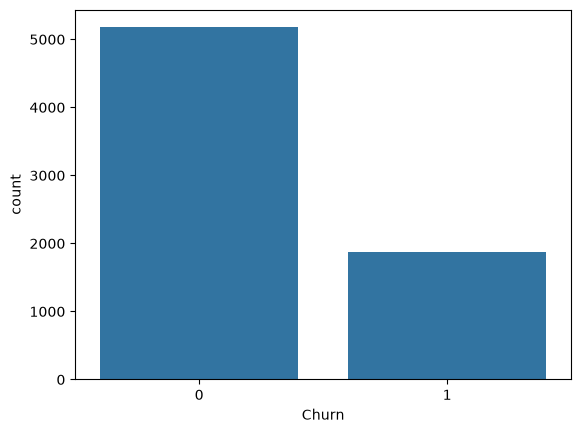

In [69]:
sns.countplot(data=df_new,x="Churn")

Text(0.5, 1.0, 'Churn %')

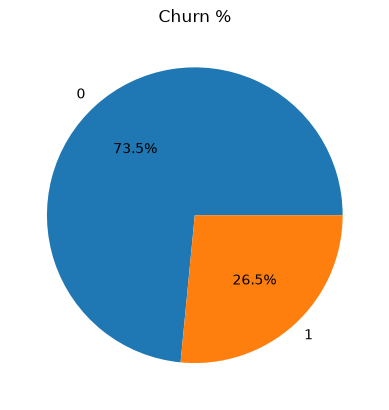

In [70]:
df_new["Churn"].value_counts().plot.pie(autopct ="%1.1f%%")
plt.title("Churn %")

In [71]:
# Decision Tree Algo

In [72]:
df_new

,gender,Partner,Dependents,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,Churn,SeniorCitizen,tenure,MonthlyCharges,TotalCharges
0,0,1,0,0,1,0,0,2,0,0,0,0,0,1,2,0,0,1,29.85,29.85
1,1,0,0,1,0,0,2,0,2,0,0,0,1,0,3,0,0,34,56.95,1889.50
2,1,0,0,1,0,0,2,2,0,0,0,0,0,1,3,1,0,2,53.85,108.15
3,1,0,0,0,1,0,2,0,2,2,0,0,1,0,0,0,0,45,42.30,1840.75
4,0,0,0,1,0,1,0,0,0,0,0,0,0,1,2,1,0,2,70.70,151.65
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,1,1,1,1,2,0,2,0,2,2,2,2,1,1,3,0,0,24,84.80,1990.50
7039,0,1,1,1,2,1,0,2,2,0,2,2,1,1,1,0,0,72,103.20,7362.90
7040,0,1,1,0,1,0,2,0,0,0,0,0,0,1,2,0,0,11,29.60,346.45
7041,1,1,0,1,2,1,0,0,0,0,0,0,0,1,3,1,1,4,74.40,306.60


In [73]:
from sklearn.tree import DecisionTreeClassifier

In [74]:
dc =DecisionTreeClassifier(random_state=42)

In [75]:
dc.fit(X_train_resample,y_train_resample)

y_pred =dc.predict(X_test)

In [76]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      0.78      0.80      1550
           1       0.48      0.57      0.52       563

    accuracy                           0.72      2113
   macro avg       0.66      0.68      0.66      2113
weighted avg       0.74      0.72      0.73      2113



In [77]:
y_prob =dc.predict_proba(X_test)[:,1]

In [78]:
print(roc_auc_score(y_test,y_prob))

0.674907465765198


In [79]:
dc.score(X_train_resample,y_train_resample)

0.9991721854304636

In [80]:
dc.score(X_test,y_test)

0.722669190724089

In [81]:
dc1 =DecisionTreeClassifier(max_depth=2)

In [82]:
dc1.fit(X_train_resample,y_train_resample)

y_pred_dc1 =dc1.predict(X_test)

In [83]:
print(classification_report(y_test,y_pred_dc1))

              precision    recall  f1-score   support

           0       0.88      0.75      0.81      1550
           1       0.51      0.71      0.59       563

    accuracy                           0.74      2113
   macro avg       0.69      0.73      0.70      2113
weighted avg       0.78      0.74      0.75      2113



In [84]:
from sklearn.tree import plot_tree

[Text(0.5, 0.8333333333333334, '[0.         0.         0.         1.         0.         0.\n 0.         0.         1.         1.         0.         0.\n 0.         0.         0.66666667 0.         0.13888889 0.35724963\n 0.06519792] <= 0.497\ngini = 0.5\nsamples = 7248\nvalue = [3624, 3624]\nclass = No'),
 Text(0.25, 0.5, '[1.         0.         0.         1.         0.         0.\n 1.         1.         0.         0.         0.         0.\n 0.5        1.         1.         0.         0.91666667 0.36273044\n 0.39831747] <= 0.499\ngini = 0.431\nsamples = 4881\nvalue = [1537.0, 3344.0]\nclass = Yes'),
 Text(0.375, 0.6666666666666667, 'True  '),
 Text(0.125, 0.16666666666666666, 'gini = 0.372\nsamples = 3651\nvalue = [902, 2749]\nclass = Yes'),
 Text(0.375, 0.16666666666666666, 'gini = 0.499\nsamples = 1230\nvalue = [635, 595]\nclass = No'),
 Text(0.75, 0.5, '[1.         0.         0.         1.         0.         1.\n 0.5        0.5        0.5        0.5        0.5        0.5\n 0.       

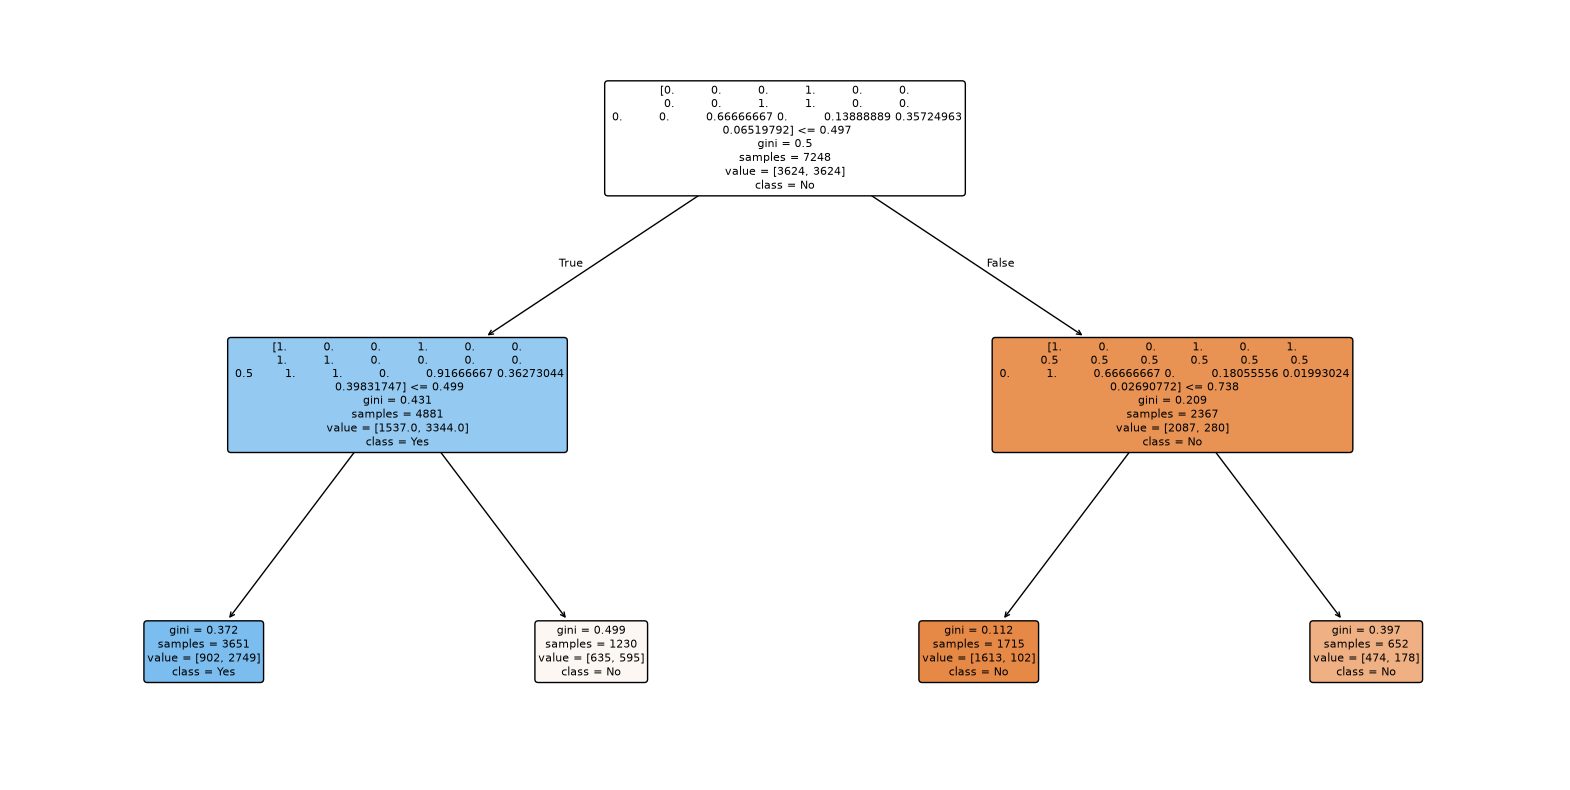

In [85]:
plt.figure(figsize=(20,10))

plot_tree(
    dc1,
    feature_names=X_train_resample,
    class_names=["No","Yes"],
    filled= True,
    rounded=True,
    fontsize=8
)

# Random Forest 

In [86]:
from sklearn.ensemble import RandomForestClassifier

In [87]:
rf =RandomForestClassifier(n_estimators=100,random_state=42)

In [88]:
rf.fit(X_train_resample,y_train_resample)

y_pred_rf =rf.predict(X_test)

In [89]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       0.85      0.85      0.85      1550
           1       0.59      0.58      0.58       563

    accuracy                           0.78      2113
   macro avg       0.72      0.72      0.72      2113
weighted avg       0.78      0.78      0.78      2113



In [90]:
y_prob_rf =rf.predict_proba(X_test)[:,1]

In [91]:
roc_auc_score(y_test,y_prob_rf)

0.8254036555320002

In [92]:
confusion_matrix(y_test,y_pred_rf)

array([[1322,  228],
       [ 236,  327]])

# Support Vector Machine 

In [93]:
from sklearn.svm import SVC

In [94]:
sv =SVC(kernel="rbf",random_state=42,probability=True)

In [95]:
sv.fit(X_train_resample,y_train_resample)

y_pred_sv=sv.predict(X_test)

C:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


In [96]:
print(classification_report(y_test,y_pred_sv))

              precision    recall  f1-score   support

           0       0.88      0.78      0.82      1550
           1       0.53      0.70      0.61       563

    accuracy                           0.76      2113
   macro avg       0.71      0.74      0.71      2113
weighted avg       0.79      0.76      0.77      2113



# Apply Cross validation

In [97]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import KFold,StratifiedKFold,cross_val_score
from sklearn.model_selection import cross_validate
from imblearn.over_sampling import SMOTE

In [98]:
lg_pipeline =Pipeline([
    ("scalar",MinMaxScaler()),
    ("smote",SMOTE(random_state=42)),
    ("model",LogisticRegression(max_iter=1000))
])

In [99]:
# Cross validation

cv =StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [100]:
score =cross_validate(
    lg_pipeline,
    X_train_resample,
    y_train_resample,
    cv= cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"],
    return_train_score=False
)

In [101]:
after_cv =pd.DataFrame({
    "Accuracy":score["test_accuracy"],
    "Precision":score["test_precision"],
    "recall":score["test_recall"],
    "f1_score":score["test_f1"],
    "roc_auc":score["test_roc_auc"]
})

In [102]:
after_cv.mean().round(3)

Accuracy     0.776
Precision    0.753
recall       0.824
f1_score     0.787
roc_auc      0.853
dtype: float64

In [103]:
print(accuracy_score(y_test, y_pred))

0.722669190724089


In [104]:
from imblearn.pipeline import Pipeline

# Step 1- Create a pipeline

rf_pipeline = Pipeline([
    ("scaler", MinMaxScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42, n_jobs=1))
])

# Step 2 -Define the parameter grid

param_grid_rf = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [5, 10, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

# Step 3 -Cross Validation

cv_rf =StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state =42
)


# Import the tunning 
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV
#Step 4 -Hyperparameter tunning

grid_search_rf = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid_rf,
    cv=cv_rf,
    scoring="f1",
    n_jobs=-1
)

# Step 5- Traing the model

grid_search_rf.fit(X_train, y_train)



,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [5, 10, ...], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], 'model__n_estimators': [100, 200]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0

In [105]:
# Step 6 - Best parameter

grid_search_rf.best_params_


{'model__max_depth': 5,
 'model__min_samples_leaf': 2,
 'model__min_samples_split': 5,
 'model__n_estimators': 200}

In [106]:
grid_search_rf.best_score_

np.float64(0.6325024633168365)

In [107]:
best_estimator =grid_search_rf.best_estimator_

In [108]:
y_pred_rf_et =best_estimator.predict(X_test)



In [109]:
confusion_matrix(y_test,y_pred_rf_et)

array([[1137,  413],
       [ 121,  442]])

In [110]:
print(classification_report(y_test,y_pred_rf_et))

              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1550
           1       0.52      0.79      0.62       563

    accuracy                           0.75      2113
   macro avg       0.71      0.76      0.72      2113
weighted avg       0.80      0.75      0.76      2113



In [113]:
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier)


In [114]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# Train
bagging_model.fit(X_train, y_train)

# Predict
y_pred_bag = bagging_model.predict(X_test)
y_prob_bag = bagging_model.predict_proba(X_test)[:, 1]

# Evaluate
print("Bagging Accuracy:", accuracy_score(y_test, y_pred_bag))
print(classification_report(y_test, y_pred_bag))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_bag))

Bagging Accuracy: 0.7870326549929011
              precision    recall  f1-score   support

           0       0.83      0.90      0.86      1550
           1       0.63      0.48      0.55       563

    accuracy                           0.79      2113
   macro avg       0.73      0.69      0.70      2113
weighted avg       0.77      0.79      0.78      2113

ROC-AUC: 0.8175379590901277


# Apply Boosting 

# AdaBoost

In [120]:
ada_boost =AdaBoostClassifier(
    estimator=RandomForestClassifier(max_depth=5,min_samples_split=5,min_samples_leaf=2,n_jobs=1),
    n_estimators=200,
    learning_rate=1.0,
    random_state=42
)

#Training the model

ada_boost.fit(X_train,y_train)

# Prediction

y_pred_ada =ada_boost.predict(X_test)
y_prob_ada =ada_boost.predict_proba(X_test)[:,-1]

# Evaluate
print("Bagging Accuracy:", accuracy_score(y_test, y_pred_ada))
print(classification_report(y_test, y_pred_ada))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_ada))

Bagging Accuracy: 0.754850922858495
              precision    recall  f1-score   support

           0       0.82      0.85      0.84      1550
           1       0.54      0.49      0.52       563

    accuracy                           0.75      2113
   macro avg       0.68      0.67      0.68      2113
weighted avg       0.75      0.75      0.75      2113

ROC-AUC: 0.7857285280467542


# Apply GradientBoosting

In [126]:
gb_boost =GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)


# Training 

gb_boost.fit(X_train,y_train)


y_pred_gb =gb_boost.predict(X_test)
y_prob_gb =gb_boost.predict_proba(X_test)[:,-1]


# Evaluate
print("Bagging Accuracy:", accuracy_score(y_test, y_pred_gb))
print(classification_report(y_test, y_pred_gb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_gb))


Bagging Accuracy: 0.7879791765262659
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1550
           1       0.63      0.51      0.56       563

    accuracy                           0.79      2113
   macro avg       0.73      0.70      0.71      2113
weighted avg       0.78      0.79      0.78      2113

ROC-AUC: 0.8249246547871426


# Xgb Boost

In [127]:
!pip install xgboost

   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.5 MB/s eta 0:00:33
   - -------------------------------------- 1.6/48.9 MB 3.3 MB/s eta 0:00:15
   --- ------------------------------------ 3.9/48.9 MB 6.1 MB/s eta 0:00:08
   ----- ---------------------------------- 6.8/48.9 MB 7.7 MB/s eta 0:00:06
   ---------- ----------------------------- 12.6/48.9 MB 11.5 MB/s eta 0:00:04
   ---------------- ----------------------- 19.7/48.9 MB 15.1 MB/s eta 0:00:02
   ------------------- -------------------- 23.3/48.9 MB 16.2 MB/s eta 0:00:02
   ------------------------ --------------- 29.9/48.9 MB 17.3 MB/s eta 0:00:02
   ----------------------------- ---------- 36.4/48.9 MB 18.8 MB/s eta 0:00:01
   ---------------------------------- ----- 42.2/48.9 MB 19.8 MB/s eta 0:00:01
   ------------------------------------ --- 44.3/48.9 MB 18.8 MB/s eta 0:00:01


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\hp\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [131]:
from xgboost import XGBClassifier

xgb_boost =XGBClassifier(
    n_estimators =100,
    learning_rate =0.1,
    max_depth =5,
    eval_metric ="logloss",
    random_state =42,
    n_jobs =1
    
)



xgb_boost.fit(X_train,y_train)

y_pred_xgb =xgb_boost.predict(X_test)
y_prob_xgb =xgb_boost.predict_proba(X_test)[:,-1]

# Evaluate
print("Bagging Accuracy:", accuracy_score(y_test, y_pred_xgb))
print(classification_report(y_test, y_pred_xgb))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_xgb))

Bagging Accuracy: 0.7983909133932797
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1550
           1       0.66      0.51      0.57       563

    accuracy                           0.80      2113
   macro avg       0.75      0.71      0.72      2113
weighted avg       0.79      0.80      0.79      2113

ROC-AUC: 0.8403134131667908
